# ETL_Traffic_Data_Analysis_Ipsit_Mohanty

# Traffic Collision Data Analysis

# Objective

In this case study, you will be working on California Traffic Collision Data Analysis using Apache Spark, a powerful distributed computing framework designed for big data processing. This assignment aims to provide hands-on experience in analyzing large-scale traffic collision datasets using PySpark and AWS services. You will apply data analytics techniques to clean, transform, and explore crash data, drawing meaningful insights to support traffic safety and urban planning. Beyond understanding how big data tools optimize performance on a single machine and across clusters, you will develop a structured approach to analyzing crash trends, identifying high-risk locations, and evaluating contributing factors to traffic incidents. Additionally, you will utilize AWS S3 to store the processed data efficiently after the ETL process, enabling scalable storage and easy retrieval for further analysis.


# Business Value:

Traffic collisions pose significant risks to public safety, requiring continuous monitoring and analysis to enhance road safety measures. Government agencies, city planners, and policymakers must leverage data-driven insights to improve infrastructure, optimize traffic management, and implement preventive measures.

In this assignment, you will analyze California traffic collision data to uncover patterns related to accident severity, location-based risks, and key contributing factors. With Apache Spark's ability to handle large datasets efficiently and AWS S3's scalable storage, transportation authorities can process vast amounts of crash data in real time, enabling faster and more informed decision-making.

As an analyst examining traffic safety trends, your task is to analyze historical crash data to derive actionable insights that can drive policy improvements and safety interventions. Your analysis will help identify high-risk areas, categorize accidents by severity and contributing factors, and store the processed data in an AWS S3 bucket for scalable and long-term storage.

By leveraging big data analytics and cloud-based storage, urban planners and traffic authorities can enhance road safety strategies, reduce accident rates, and improve public transportation planning.


# Dataset Overview

The dataset used in this analysis consists of California traffic collision data obtained from the Statewide Integrated Traffic Records System (SWITRS). It includes detailed records of traffic incidents across California, covering various attributes such as location, severity, involved parties, and contributing factors. The dataset has been preprocessed and transformed using PySpark to facilitate large-scale analysis. By leveraging Apache Spark, we ensure efficient data handling, enabling deeper insights into traffic patterns, accident trends, and potential safety improvements.

The dataset is a .sqlite file contains detailed information about traffic collisions across California and is structured into four primary tables:
- `collisions` table contains information about the collision, where it happened, what vehicles were involved.

- `parties` table contains information about the groups people involved in the collision including age, sex, and sobriety.

- `victims` table contains information about the injuries of specific people involved in the collision.

- `locations` table contains information about the geographical location and details of road intersections.

# Assignment Tasks

<ol>
    <li>
        <strong>Data Preparation</strong></br>
        The dataset consists of structured tables containing traffic collision data. Before conducting any analysis, it is essential to ensure that the data is properly formatted and structured for efficient processing.</br>
        Check for data consistency and ensure all columns are correctly formatted.</br>
        Apply sampling techniques if needed to extract a representative subset for analysis.</br>
        Structure and prepare the data for further processing and analysis.</br>
    </br>
    <li>
        <strong>Data Cleaning</strong></br>
            2.1 <strong>Fixing Columns:</strong> Ensure all columns are properly named and formatted.</br>
            2.2 <strong>Handling Missing Values:</strong> Decide on an approach to handle missing data (e.g., imputation or removal). Mention the approach in your report.</br>
            2.3 <strong>Handling Outliers:</strong> Identify outliers in the dataset and explain why they are considered outliers. It is not necessary to remove them for this task, but mention your approach for handling them.</br>
    </br>
    <li>
        <strong>Exploratory Data Analysis</strong></br>
        Finding Patterns and analyze the dataset and find patterns based on the following points:
                <ul>
                3.1 Classify variables into categorical and numerical types.</br>
                3.2 Analyze the distribution of collision severity.</br>
                3.3 Examine weather conditions during collisions.</br>
                3.4 Analyze the distribution of victim ages.</br>
                3.5 Study the relationship between collision severity and the number of victims.</br>
                3.6 Analyze the correlation between weather conditions and collision severity.</br>
                3.7 Visualize the impact of lighting conditions on collision severity.</br>
                3.8 Extract and analyze weekday-wise collision trends.</br>
                3.9 Assess the number of collisions occurring on different days of the week.</br>
                3.10 Study spatial distribution of collisions by county.</br>
                3.11 Generate a scatter plot to analyze collision locations geographically.</br>
                3.12 Extract and analyze collision trends over time, including yearly, monthly, and hourly trends.</br>
</ul>
</br>
<li>
<strong>ETL Querying</strong><br>
Write PySpark SQL queries for the following:</br>
<ol>
    4.1. Identify the top 5 counties with the highest number of collisions.</br>
    4.2. Identify the month with the highest number of collisions.</br>
    4.3. Determine the most common weather condition during collisions.</br>
    4.4. Calculate the percentage of collisions that resulted in fatalities.</br>
    4.5. Find the most dangerous time of day for collisions.</br>
    4.6. Identify the top 5 road surface conditions with the highest collision frequency.</br>
    4.7. Analyze lighting conditions that contribute to the highest number of collisions.</br>
</ol>
</br>
<li>
<strong>Conclusion</strong></br>
Provide final insights and recommendations based on the analysis:
    <ul>
        5.1 Recommendations to improve road safety by identifying high-risk locations and peak accident times for infrastructure improvements.</br>
        5.2 Suggestions to optimize traffic management by analyzing trends in collision severity, weather conditions, and lighting to improve road design and traffic signal timing.</br>
        5.3 Propose data-driven policy changes to enhance pedestrian and cyclist safety based on collision trends involving vulnerable road users.</br>
        5.4 Identify potential high-risk zones for proactive intervention by examining geographic collision density and historical accident data.</br>
        5.5 Assess the impact of environmental factors such as weather, road surface conditions, and lighting on accident frequency and severity.</br>
        5.6 Develop predictive models to anticipate collision hotspots and support proactive safety measures.</br>
        </ul>
        Conclude the analysis by summarizing key findings and business implications.</br>
        Explain the results of univariate, segmented univariate, and bivariate analyses in real-world traffic safety and policy terms.</br>
        Include visualizations and summarize the most important results in the report. Insights should explain why each variable is important and how they can influence traffic safety policies and urban planning.</br>
        </ul>
        </br>
    <li>
    <strong>Visualization Integration [Optional]</strong>
    <p>Enhance the project by incorporating a visualization component that connects the processed data stored in an S3 bucket to a business intelligence tool such as Tableau or Power BI. This involves setting up the connection between the S3 bucket and the chosen visualization tool, importing the processed dataset for analysis and visualization, creating interactive dashboards to explore key trends and insights and ensuring data updates are reflected dynamically in the visualization tool.<br>
</br>
</ol>

In [1]:
# from google.colab import drive
# drive.mount('/content/drive')

Install Required Libraries

In [2]:
## Install the required libraries
# !pip install --quiet pyspark==3.5.4 pandas==2.2.2

In [3]:
# Import the necessary libraries
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pyspark.sql import SparkSession
from pyspark.sql.functions import col, sum, to_date, year, month, hour, dayofweek, when, count
from pyspark.sql.types import IntegerType

In [4]:
!pip install pyspark

#**1. Data Preparation** <font color = red>[5 marks]</font> <br>

The dataset consists of structured tables containing traffic collision data.

Before conducting any analysis, it is essential to ensure that the data is properly formatted and structured for efficient processing.

Check for data consistency and ensure all columns are correctly formatted.

In [5]:
# Write code to load the data and check the schema

# Initialize Spark Session
spark = SparkSession.builder \
    .appName("TrafficCollisionAnalysis") \
    .config("spark.driver.memory", "8g") \
    .getOrCreate()

# Keep the console output clean
spark.sparkContext.setLogLevel("WARN") 

# Define paths
base_path = "D:/downloads/Crash_Data_Analysis_Dataset/"
collisions_path = base_path + "sample_collisions.csv"
parties_path = base_path + "sample_parties.csv"
victims_path = base_path + "sample_victims.csv"

print("Loading collisions data...")
collisions_df = spark.read.csv(collisions_path, header=True, inferSchema=True)

print("Loading parties data...")
parties_df = spark.read.csv(parties_path, header=True, inferSchema=True)

print("Loading victims data...")
victims_df = spark.read.csv(victims_path, header=True, inferSchema=True)

# Task 1 Check: Print Schema and Sample
print("\n--- Collisions Table Schema ---")
collisions_df.printSchema()
print("\n--- Sample Data ---")
collisions_df.show(5, truncate=False)


Loading collisions data...
Loading parties data...
Loading victims data...

--- Collisions Table Schema ---
root
 |-- case_id: double (nullable = true)
 |-- jurisdiction: double (nullable = true)
 |-- officer_id: string (nullable = true)
 |-- reporting_district: string (nullable = true)
 |-- chp_shift: string (nullable = true)
 |-- population: string (nullable = true)
 |-- county_city_location: integer (nullable = true)
 |-- county_location: string (nullable = true)
 |-- special_condition: double (nullable = true)
 |-- beat_type: string (nullable = true)
 |-- chp_beat_type: string (nullable = true)
 |-- chp_beat_class: string (nullable = true)
 |-- beat_number: string (nullable = true)
 |-- primary_road: string (nullable = true)
 |-- secondary_road: string (nullable = true)
 |-- distance: double (nullable = true)
 |-- direction: string (nullable = true)
 |-- intersection: double (nullable = true)
 |-- weather_1: string (nullable = true)
 |-- state_highway_indicator: double (nullable = 

#**2. Data Cleaning** <font color = red>[20 marks]</font> <br>


In [6]:
# Display Schema and Sample Data
collisions_df.printSchema()
collisions_df.show(3, truncate=False)

root
 |-- case_id: double (nullable = true)
 |-- jurisdiction: double (nullable = true)
 |-- officer_id: string (nullable = true)
 |-- reporting_district: string (nullable = true)
 |-- chp_shift: string (nullable = true)
 |-- population: string (nullable = true)
 |-- county_city_location: integer (nullable = true)
 |-- county_location: string (nullable = true)
 |-- special_condition: double (nullable = true)
 |-- beat_type: string (nullable = true)
 |-- chp_beat_type: string (nullable = true)
 |-- chp_beat_class: string (nullable = true)
 |-- beat_number: string (nullable = true)
 |-- primary_road: string (nullable = true)
 |-- secondary_road: string (nullable = true)
 |-- distance: double (nullable = true)
 |-- direction: string (nullable = true)
 |-- intersection: double (nullable = true)
 |-- weather_1: string (nullable = true)
 |-- state_highway_indicator: double (nullable = true)
 |-- caltrans_county: string (nullable = true)
 |-- caltrans_district: double (nullable = true)
 |-- s

##**2.1 Missing Values** <font color = red>[10 marks]</font> <br>


In [7]:
from pyspark.sql.functions import count, when, col

# Get total row count
total_rows = collisions_df.count()

# Calculate missing values safely
# We cast the column to string first so comparing to "" doesn't crash on Double columns
missing_counts = collisions_df.select([
    count(when(col(c).isNull() | (col(c).cast("string") == ""), c)).alias(c) for c in collisions_df.columns
])

# Convert to pandas to easily view, sort, and calculate percentages
missing_df = missing_counts.toPandas().T
missing_df.columns = ['Missing_Count']
missing_df['Missing_Percentage'] = (missing_df['Missing_Count'] / total_rows) * 100

# Display columns that actually have missing data, sorted highest to lowest
missing_df = missing_df[missing_df['Missing_Count'] > 0]
print(f"Total Rows: {total_rows}")
display(missing_df.sort_values(by='Missing_Percentage', ascending=False).head(20))

Total Rows: 935791


,Missing_Count,Missing_Percentage
side_of_highway,682077,72.887750
caltrans_county,682075,72.887536
location_type,682075,72.887536
latitude,669049,71.495558
longitude,669049,71.495558
postmile,648728,69.324026
caltrans_district,648728,69.324026
state_route,648728,69.324026
pcf_violation_subsection,601427,64.269372
reporting_district,552653,59.057311


In [8]:
#Drop Sparse Columns

# Identify columns with more than 60% missing data
keep_cols = ['latitude', 'longitude']
cols_to_drop = [c for c in missing_df[missing_df['Missing_Percentage'] > 60].index.tolist() if c not in keep_cols]

print(f"Dropping {len(cols_to_drop)} highly sparse columns:")
print(cols_to_drop)

# Drop the columns
collisions_clean_df = collisions_df.drop(*cols_to_drop)

Dropping 7 highly sparse columns:
['caltrans_county', 'caltrans_district', 'state_route', 'postmile', 'location_type', 'side_of_highway', 'pcf_violation_subsection']


In [9]:
#Convert Data Types

from pyspark.sql.types import IntegerType

# 1. case_id is kept as double: some ids are ~9.8E18 (beyond BIGINT range), and the victims table
#    reads case_id as double too, so the two tables join directly without any string conversion.

# 2. Convert specific count columns from Double to Integer
count_cols = [
    "killed_victims", "injured_victims", "party_count", 
    "motorcyclist_injured_count", "pedestrian_killed_count", 
    "pedestrian_injured_count", "bicyclist_killed_count", 
    "bicyclist_injured_count"
]

for c in count_cols:
    if c in collisions_clean_df.columns:
        collisions_clean_df = collisions_clean_df.withColumn(c, col(c).cast(IntegerType()))

print("Data types converted successfully.")
# Verify the changes
collisions_clean_df.select("case_id", "killed_victims", "injured_victims").printSchema()


Data types converted successfully.
root
 |-- case_id: double (nullable = true)
 |-- killed_victims: integer (nullable = true)
 |-- injured_victims: integer (nullable = true)



In [10]:
#Handle Missing Values

# 1. Fill categorical (string) columns with "Unknown"
cat_cols_to_fill = ["weather_1", "road_surface", "road_condition_1", "lighting", "primary_collision_factor", "type_of_collision"]
for c in cat_cols_to_fill:
    if c in collisions_clean_df.columns:
        collisions_clean_df = collisions_clean_df.fillna({c: "Unknown"})

# 2. Fill numerical (count) columns with 0
num_cols_to_fill = ["killed_victims", "injured_victims", "party_count", "motorcyclist_injured_count"]
for c in num_cols_to_fill:
    if c in collisions_clean_df.columns:
        collisions_clean_df = collisions_clean_df.fillna({c: 0})

print("Missing values handled successfully.")


Missing values handled successfully.


##**2.2 Fixing Columns** <font color = red>[5 marks]</font> <br>


In [11]:
#Remove Duplicates

initial_count = collisions_clean_df.count()
collisions_clean_df = collisions_clean_df.dropDuplicates()
final_count = collisions_clean_df.count()
print(f"Removed {initial_count - final_count} duplicate rows.")

Removed 0 duplicate rows.


In [12]:
#Detect Outliers using IQR


# List of numerical columns to check for outliers

# List of numerical columns to check for outliers
outlier_cols = ["injured_victims", "killed_victims", "party_count"]

for c in outlier_cols:
    if c in collisions_clean_df.columns:
        # Calculate 25th and 75th percentiles
        quantiles = collisions_clean_df.approxQuantile(c, [0.25, 0.75], 0.05)
        Q1 = quantiles[0]
        Q3 = quantiles[1]
        IQR = Q3 - Q1
        
        lower_bound = Q1 - 1.5 * IQR
        upper_bound = Q3 + 1.5 * IQR
        
        # Count how many rows fall outside the bounds
        outliers_count = collisions_clean_df.filter((col(c) < lower_bound) | (col(c) > upper_bound)).count()
        print(f"Column '{c}': Found {outliers_count} outliers. (Bounds: {lower_bound} to {upper_bound})")


Column 'injured_victims': Found 33313 outliers. (Bounds: -1.5 to 2.5)
Column 'killed_victims': Found 0 outliers. (Bounds: 0.0 to 0.0)
Column 'party_count': Found 298314 outliers. (Bounds: 2.0 to 2.0)


##**2.3 Outlier Analysis** <font color = red>[5 marks]</font> <br>


In [13]:
#Remove Outliers

# - party_count is discrete with Q1 = Q3 = 2, so IQR = 0 and every count other than 2 is flagged.
#   These are valid multi-vehicle / single-vehicle crashes, not errors.
# - injured_victims: 3+ injured is rare but real (pile-ups).
# - killed_victims is 0 for every row in this sample, so it has no outliers.
# - Approach: retain all of them; use medians/counts, consider a log transform if modelling later.
print("Outliers identified but retained for analysis.")

Outliers identified but retained for analysis.


#**3. Exploratory Data Analysis** <font color = red>[65 marks]</font> <br>


##**3.1.1. Data Preparation** <font color = red>[5 marks]</font> <br>

Q: Classify variables into categorical and numerical.

In [14]:
# Encode Categorical Variables

# String Indexing for Categorical Columns

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Set a nice visual style for the plots
sns.set_theme(style="whitegrid")

# Answer the question: Classify variables into categorical and numerical
categorical_cols = ['collision_severity', 'weather_1', 'road_surface', 'lighting', 'type_of_collision']
numerical_cols = ['injured_victims', 'killed_victims', 'party_count']

print("Categorical Variables identified:", categorical_cols)
print("Numerical Variables identified:", numerical_cols)

# --- Convert to Pandas ---
print("\nConverting to Pandas for EDA (This may take 10-20 seconds)...")
collisions_pd = collisions_clean_df.toPandas()

print(f"Success! Pandas DataFrame Shape: {collisions_pd.shape}")


Categorical Variables identified: ['collision_severity', 'weather_1', 'road_surface', 'lighting', 'type_of_collision']
Numerical Variables identified: ['injured_victims', 'killed_victims', 'party_count']

Converting to Pandas for EDA (This may take 10-20 seconds)...
Success! Pandas DataFrame Shape: (935791, 58)


In [15]:
# Reordering & Renaming Columns
from pyspark.ml.feature import StringIndexer

# String-index (label-encode) the categorical columns
indexed_df = collisions_clean_df
for c_name in categorical_cols:
    indexer = StringIndexer(inputCol=c_name, outputCol=f"{c_name}_idx", handleInvalid="keep")
    indexed_df = indexer.fit(indexed_df).transform(indexed_df)

# Reorder: identifier -> date/time -> location -> categorical -> encoded -> numeric -> rest
front = (["case_id", "collision_date", "collision_time", "county_location", "latitude", "longitude"]
         + categorical_cols + [f"{c_name}_idx" for c_name in categorical_cols] + numerical_cols)
front = [c_name for c_name in front if c_name in indexed_df.columns]
rest = [c_name for c_name in indexed_df.columns if c_name not in front]
final_df = indexed_df.select(front + rest)

# Rename to clearer names (final_df only; the EDA below keeps the original names)
rename_map = {"weather_1": "weather_condition", "road_condition_1": "road_condition",
              "county_location": "county", "lighting": "lighting_condition"}
for old, new in rename_map.items():
    if old in final_df.columns:
        final_df = final_df.withColumnRenamed(old, new)

show_cols = [rename_map.get(c_name, c_name) for c_name in front[:12]]
final_df.select(show_cols).show(5, truncate=False)

+---------+--------------+-------------------+---------+--------+----------+--------------------+-----------------+------------+-----------------------+-----------------+----------------------+
|case_id  |collision_date|collision_time     |county   |latitude|longitude |collision_severity  |weather_condition|road_surface|lighting_condition     |type_of_collision|collision_severity_idx|
+---------+--------------+-------------------+---------+--------+----------+--------------------+-----------------+------------+-----------------------+-----------------+----------------------+
|8935822.0|2018-07-22    |2026-10-19 14:00:00|san mateo|37.57294|-122.33125|property damage only|clear            |dry         |daylight               |rear end         |0.0                   |
|5218497.0|2011-06-23    |2026-10-19 23:28:00|san diego|32.7576 |-117.20289|other injury        |cloudy           |dry         |dark with street lights|hit object       |2.0                   |
|7205279.0|2016-02-24    |2026

In [16]:
# Final cleaned data

print("Final cleaned dataset:", final_df.count(), "rows x", len(final_df.columns), "columns")
final_df.printSchema()

# Load into storage as Parquet. For cloud, use e.g. "s3a://<bucket>/cleaned/collisions/" or "gs://<bucket>/..."
output_path = base_path + "cleaned_collisions_parquet"
try:
    final_df.write.mode("overwrite").parquet(output_path)
    print("Cleaned data written to:", output_path)
except Exception as e:
    # Spark's Parquet writer can fail on Windows without winutils/HADOOP_HOME; fall back to pandas
    print("Spark write failed, falling back to pandas:", str(e)[:120])
    final_df.toPandas().to_parquet(base_path + "cleaned_collisions.parquet", index=False)
    print("Cleaned data written to:", base_path + "cleaned_collisions.parquet")

Final cleaned dataset: 935791 rows x 63 columns
root
 |-- case_id: double (nullable = true)
 |-- collision_date: date (nullable = true)
 |-- collision_time: timestamp (nullable = true)
 |-- county: string (nullable = true)
 |-- latitude: double (nullable = true)
 |-- longitude: double (nullable = true)
 |-- collision_severity: string (nullable = true)
 |-- weather_condition: string (nullable = false)
 |-- road_surface: string (nullable = false)
 |-- lighting_condition: string (nullable = false)
 |-- type_of_collision: string (nullable = false)
 |-- collision_severity_idx: double (nullable = false)
 |-- weather_1_idx: double (nullable = false)
 |-- road_surface_idx: double (nullable = false)
 |-- lighting_idx: double (nullable = false)
 |-- type_of_collision_idx: double (nullable = false)
 |-- injured_victims: integer (nullable = false)
 |-- killed_victims: integer (nullable = false)
 |-- party_count: integer (nullable = false)
 |-- jurisdiction: double (nullable = true)
 |-- officer_id

Loading the Final Cleaned Dataset into S3 Bucket

##**3.1.2. Analyze the distribution of collision severity.** <font color = red>[5 marks]</font> <br>

Q: Analyze the distribution of collision severity.

C:\Users\ipsit\AppData\Local\Temp\ipykernel_36108\255520693.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=severity_counts.index, y=severity_counts.values, palette='viridis')


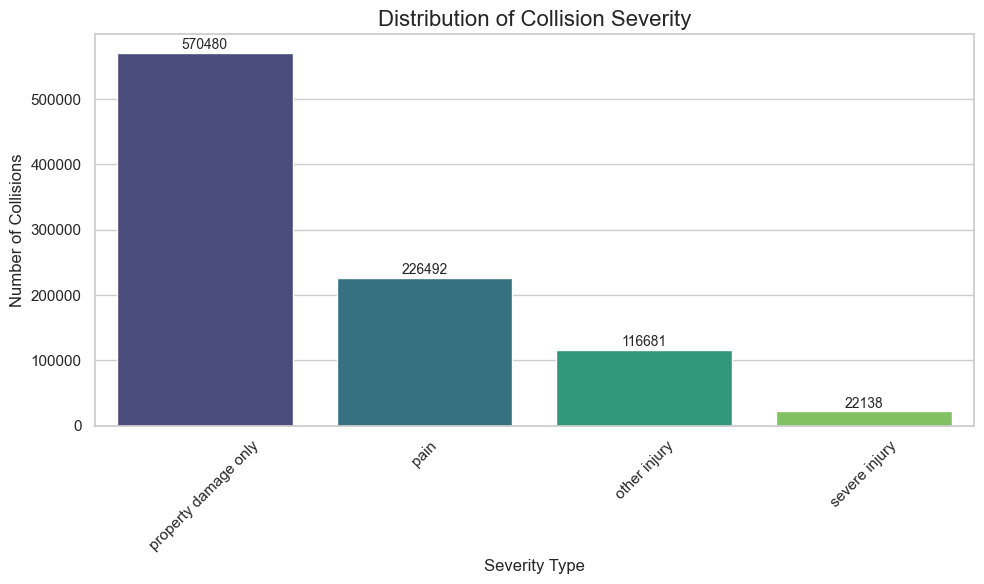

In [17]:
# Univariate Analysis

# Collision Severity Distribution

import matplotlib.pyplot as plt
import seaborn as sns

# Convert to Pandas

# Plot


severity_counts = collisions_pd['collision_severity'].value_counts()

plt.figure(figsize=(10, 6))
sns.barplot(x=severity_counts.index, y=severity_counts.values, palette='viridis')

plt.title('Distribution of Collision Severity', fontsize=16)
plt.xlabel('Severity Type', fontsize=12)
plt.ylabel('Number of Collisions', fontsize=12)
plt.xticks(rotation=45)

# Add exact count on top of the bars
for i, v in enumerate(severity_counts.values):
    plt.text(i, v + 1000, str(v), ha='center', va='bottom', fontsize=10)

plt.tight_layout()
plt.show()


##**3.1.3. Weather conditions during collisions.** <font color = red>[5 marks]</font> <br>

Q: Examine weather conditions during collisions.

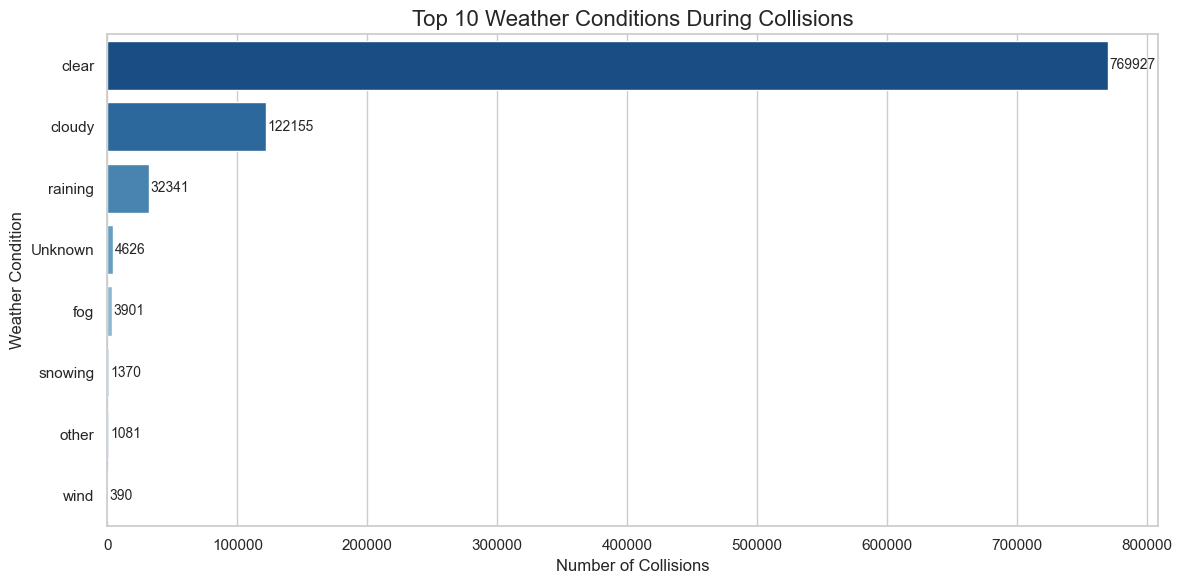

In [18]:
# Weather Conditions During Collisions

# Convert to Pandas

# Plot

# Weather Conditions During Collisions
weather_counts = collisions_pd['weather_1'].value_counts().head(10)

plt.figure(figsize=(12, 6))
# We use hue=weather_counts.index and legend=False to fix the FutureWarning
sns.barplot(x=weather_counts.values, y=weather_counts.index, hue=weather_counts.index, palette='Blues_r', legend=False)

plt.title('Top 10 Weather Conditions During Collisions', fontsize=16)
plt.xlabel('Number of Collisions', fontsize=12)
plt.ylabel('Weather Condition', fontsize=12)

# Add exact count text
for i, v in enumerate(weather_counts.values):
    plt.text(v + 1000, i, str(v), va='center', fontsize=10)

plt.tight_layout()
plt.show()


##**3.1.4. Victime Age Distribution.** <font color = red>[5 marks]</font> <br>

Q: Analyze the distribution of victim ages.

Victims columns: ['id', 'case_id', 'party_number', 'victim_role', 'victim_sex', 'victim_age', 'victim_degree_of_injury', 'victim_seating_position', 'victim_safety_equipment_1', 'victim_safety_equipment_2', 'victim_ejected']


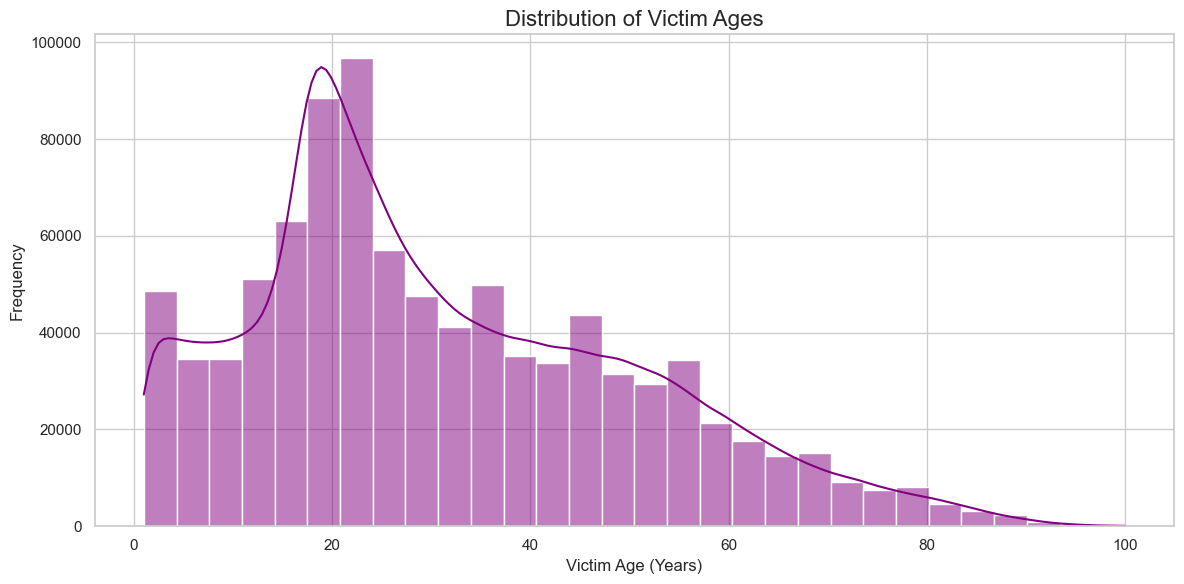

In [19]:
# Distribution of Victim Ages

# Convert to Pandas

# Plot

# Convert victims table to Pandas
victims_pd = victims_df.toPandas()

# Print columns just in case the age column has a slightly different name
print("Victims columns:", victims_pd.columns.tolist())

# Check for the correct age column name (often 'victim_age' or 'age')
age_col = 'victim_age' if 'victim_age' in victims_pd.columns else 'age'

# Filter out unrealistic ages: 0 (unknown/infant placeholder), 998/999 (SWITRS "unknown" codes), and >100; drop missing
victim_ages = victims_pd[age_col].dropna()
victim_ages = victim_ages[(victim_ages > 0) & (victim_ages <= 100)]

# Plot
plt.figure(figsize=(12, 6))
sns.histplot(victim_ages, bins=30, kde=True, color='purple')

plt.title('Distribution of Victim Ages', fontsize=16)
plt.xlabel('Victim Age (Years)', fontsize=12)
plt.ylabel('Frequency', fontsize=12)

plt.tight_layout()
plt.show()

##**3.1.5. Collision Severity vs Number of Victims.** <font color = red>[5 marks]</font> <br>

Q: Study the relationship between collision severity and the number of victims.

Collisions with a matching victims record: 9.3%
     collision_severity  Avg_Injured_Victims
0         severe injury                 1.62
1          other injury                 1.51
2                  pain                 1.37
3  property damage only                 0.00


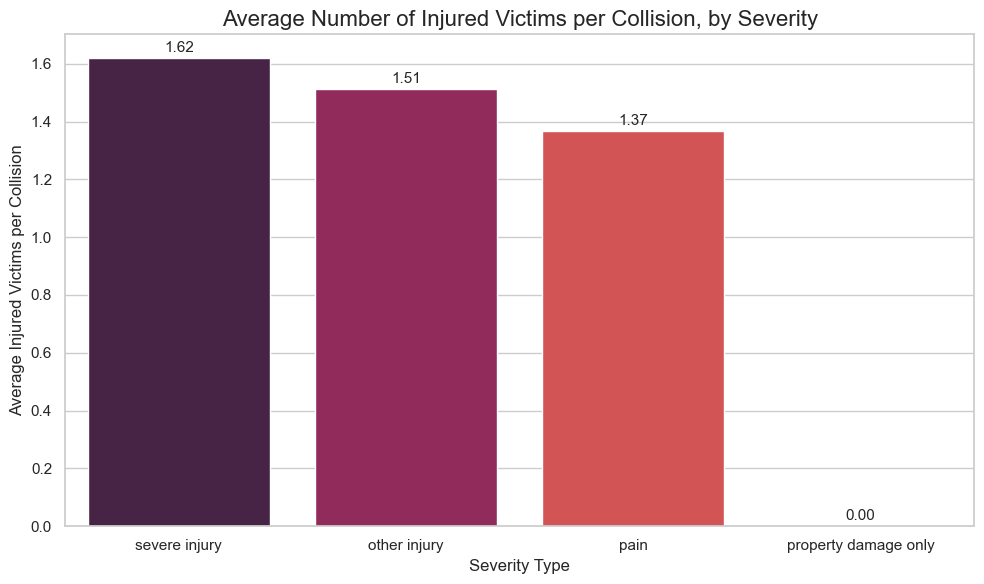

In [20]:
   # Bivariate Analysis

   # Collision Severity vs. Number of Victims
   # NOTE: the sample victims table links to only ~9% of the sampled collisions, so counting victims-table
   # rows would measure join coverage, not crash size. injured_victims is recorded on every collision.
   victims_pd['case_id'] = pd.to_numeric(victims_pd['case_id'], errors='coerce')
   collisions_pd['case_id'] = pd.to_numeric(collisions_pd['case_id'], errors='coerce')
   print(f"Collisions with a matching victims record: {collisions_pd['case_id'].isin(victims_pd['case_id']).mean():.1%}")

   avg_victims = (collisions_pd.groupby('collision_severity')['injured_victims'].mean()
                  .sort_values(ascending=False).reset_index(name='Avg_Injured_Victims'))
   print(avg_victims.round(2))

   plt.figure(figsize=(10, 6))
   sns.barplot(data=avg_victims, x='collision_severity', y='Avg_Injured_Victims', hue='collision_severity', palette='rocket', legend=False)
   for i, v in enumerate(avg_victims['Avg_Injured_Victims']):
       plt.text(i, v + 0.02, f"{v:.2f}", ha='center', fontsize=11)
   plt.title('Average Number of Injured Victims per Collision, by Severity', fontsize=16)
   plt.xlabel('Severity Type', fontsize=12)
   plt.ylabel('Average Injured Victims per Collision', fontsize=12)
   plt.tight_layout()
   plt.show()

In [21]:
   # Join collisions with victims in PySpark (inner join on case_id)
   from pyspark.sql import functions as F

   joined_df = collisions_clean_df.join(
       victims_df.select("case_id", "victim_age", "victim_degree_of_injury"), on="case_id", how="inner")

   matched = joined_df.select("case_id").distinct().count()
   total = collisions_clean_df.count()
   print(f"Joined rows: {joined_df.count():,} | collisions with a victim record: {matched:,} ({matched / total:.1%})")

   # Victim rows and matched collisions by severity
   joined_df.groupBy("collision_severity").agg(
       F.countDistinct("case_id").alias("collisions_with_victim_rows"),
       F.count("*").alias("victim_rows")).show()

Joined rows: 95,454 | collisions with a victim record: 86,973 (9.3%)
+--------------------+---------------------------+-----------+
|  collision_severity|collisions_with_victim_rows|victim_rows|
+--------------------+---------------------------+-----------+
|property damage only|                      24299|      26879|
|                pain|                      38810|      42436|
|        other injury|                      20062|      21972|
|       severe injury|                       3803|       4167|
+--------------------+---------------------------+-----------+



##**3.1.6. Weather Conditions vs Collision Severity.** <font color = red>[5 marks]</font> <br>

Q: Analyze the correlation between weather conditions and collision severity.

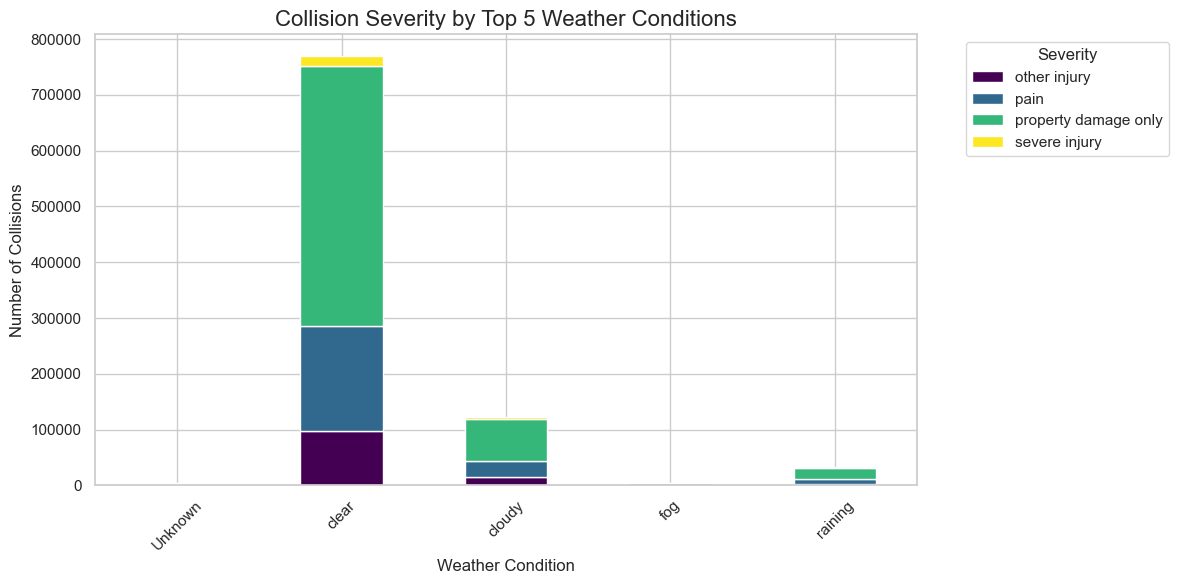

collision_severity  other injury   pain  property damage only  severe injury
weather_1                                                                   
Unknown                    12.11  25.81                 60.42           1.66
clear                      12.71  24.32                 60.55           2.42
cloudy                     11.59  23.62                 62.69           2.11
fog                        13.25  19.33                 63.83           3.59
raining                    10.32  24.62                 63.15           1.92


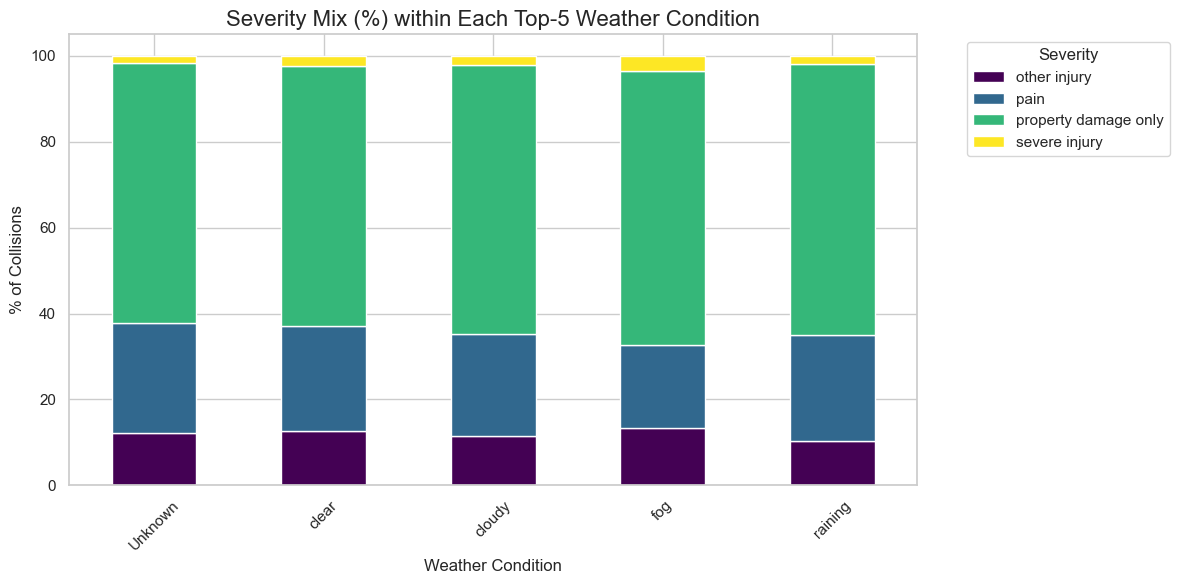

In [22]:
# Weather vs. Collision Severity

# Convert to Pandas

# Plot

# Get the top 5 weather conditions to keep the chart readable
top_weather = collisions_pd['weather_1'].value_counts().head(5).index
filtered_weather_df = collisions_pd[collisions_pd['weather_1'].isin(top_weather)]

# Create a crosstab (contingency table)
weather_severity_cross = pd.crosstab(filtered_weather_df['weather_1'], filtered_weather_df['collision_severity'])

# Plot Stacked Bar Chart
weather_severity_cross.plot(kind='bar', stacked=True, figsize=(12, 6), colormap='viridis')

plt.title('Collision Severity by Top 5 Weather Conditions', fontsize=16)
plt.xlabel('Weather Condition', fontsize=12)
plt.ylabel('Number of Collisions', fontsize=12)
plt.xticks(rotation=45)
plt.legend(title='Severity', bbox_to_anchor=(1.05, 1), loc='upper left')

plt.tight_layout()
plt.show()

# Normalised view: severity MIX within each weather condition
weather_severity_pct = pd.crosstab(filtered_weather_df['weather_1'], filtered_weather_df['collision_severity'], normalize='index') * 100
print(weather_severity_pct.round(2))
weather_severity_pct.plot(kind='bar', stacked=True, figsize=(12, 6), colormap='viridis')
plt.title('Severity Mix (%) within Each Top-5 Weather Condition', fontsize=16)
plt.xlabel('Weather Condition', fontsize=12)
plt.ylabel('% of Collisions', fontsize=12)
plt.xticks(rotation=45)
plt.legend(title='Severity', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()


##**3.1.7. Lighting conditions vs Collision Severity.** <font color = red>[5 marks]</font> <br>

Q:Visualize the impact of lighting conditions on collision severity.

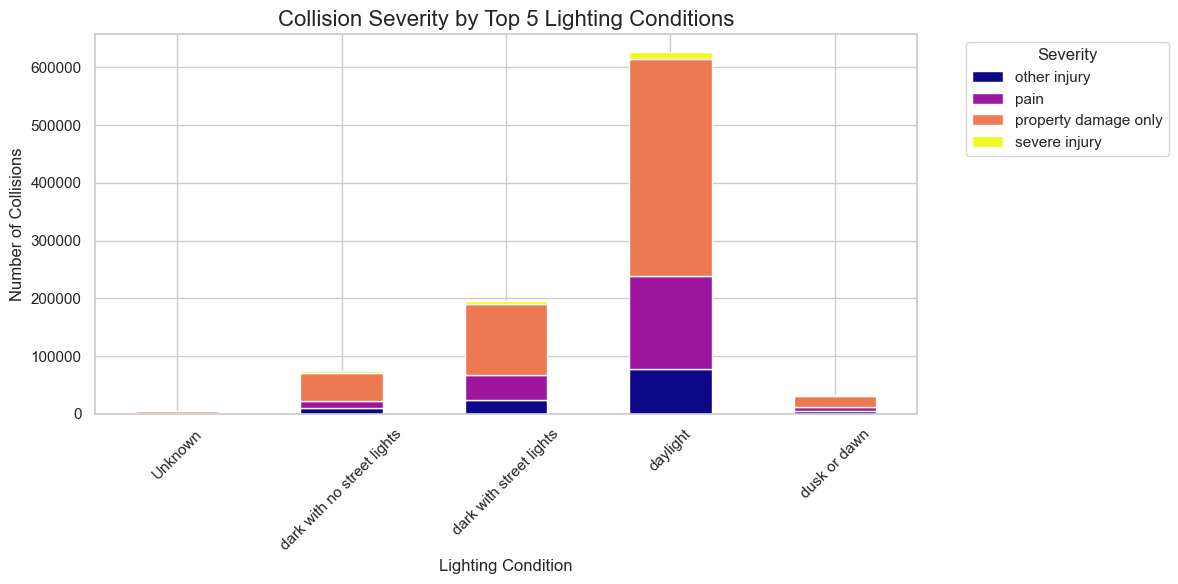

collision_severity          other injury   pain  property damage only  \
lighting                                                                
Unknown                            10.94  23.34                 64.33   
dark with no street lights         14.33  16.20                 65.13   
dark with street lights            12.11  21.89                 63.03   
daylight                           12.36  25.90                 59.82   
dusk or dawn                       12.71  24.15                 60.40   

collision_severity          severe injury  
lighting                                   
Unknown                              1.40  
dark with no street lights           4.35  
dark with street lights              2.97  
daylight                             1.92  
dusk or dawn                         2.74  


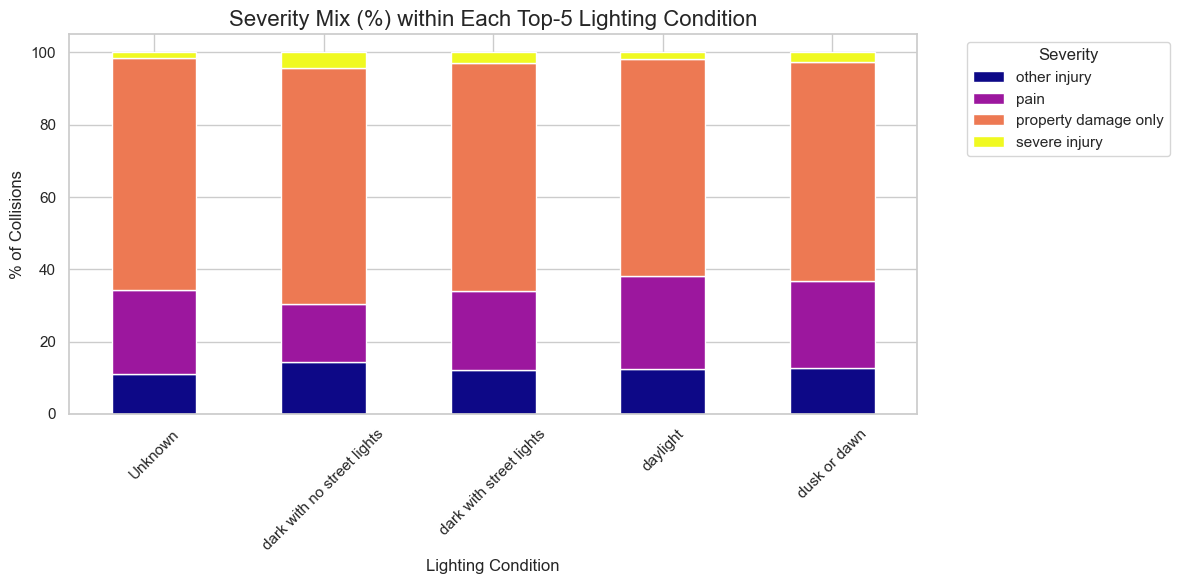

In [23]:
# Lighting Conditions vs. Collision Severity

# Convert to Pandas

# Plot

# Get the top 5 lighting conditions
top_lighting = collisions_pd['lighting'].value_counts().head(5).index
filtered_lighting_df = collisions_pd[collisions_pd['lighting'].isin(top_lighting)]

# Create a crosstab
lighting_severity_cross = pd.crosstab(filtered_lighting_df['lighting'], filtered_lighting_df['collision_severity'])

# Plot Stacked Bar Chart
lighting_severity_cross.plot(kind='bar', stacked=True, figsize=(12, 6), colormap='plasma')

plt.title('Collision Severity by Top 5 Lighting Conditions', fontsize=16)
plt.xlabel('Lighting Condition', fontsize=12)
plt.ylabel('Number of Collisions', fontsize=12)
plt.xticks(rotation=45)
plt.legend(title='Severity', bbox_to_anchor=(1.05, 1), loc='upper left')

plt.tight_layout()
plt.show()

# Normalised view: severity MIX within each lighting condition
lighting_severity_pct = pd.crosstab(filtered_lighting_df['lighting'], filtered_lighting_df['collision_severity'], normalize='index') * 100
print(lighting_severity_pct.round(2))
lighting_severity_pct.plot(kind='bar', stacked=True, figsize=(12, 6), colormap='plasma')
plt.title('Severity Mix (%) within Each Top-5 Lighting Condition', fontsize=16)
plt.xlabel('Lighting Condition', fontsize=12)
plt.ylabel('% of Collisions', fontsize=12)
plt.xticks(rotation=45)
plt.legend(title='Severity', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()


In [24]:
   # Severity share for vulnerable road users (supports the pedestrian/cyclist recommendation)
   flags = ['pedestrian_collision', 'bicycle_collision', 'motorcycle_collision', 'truck_collision']
   rows = []
   for f in flags:
       sub = collisions_pd[collisions_pd[f] == 1]
       rows.append({'type': f, 'collisions': len(sub), 'severe_injury_%': round((sub['collision_severity'] == 'severe injury').mean() * 100, 2)})
   rows.append({'type': 'all collisions', 'collisions': len(collisions_pd), 'severe_injury_%': round((collisions_pd['collision_severity'] == 'severe injury').mean() * 100, 2)})
   print(pd.DataFrame(rows))

                   type  collisions  severe_injury_%
0  pedestrian_collision       26896            13.66
1     bicycle_collision       25538             7.18
2  motorcycle_collision       27087            16.36
3       truck_collision       54322             2.01
4        all collisions      935791             2.37


##**3.1.8. Weekday-Wise Collision Trends.** <font color = red>[7 marks]</font> <br>

Q: Extract and analyze weekday-wise collision trends.

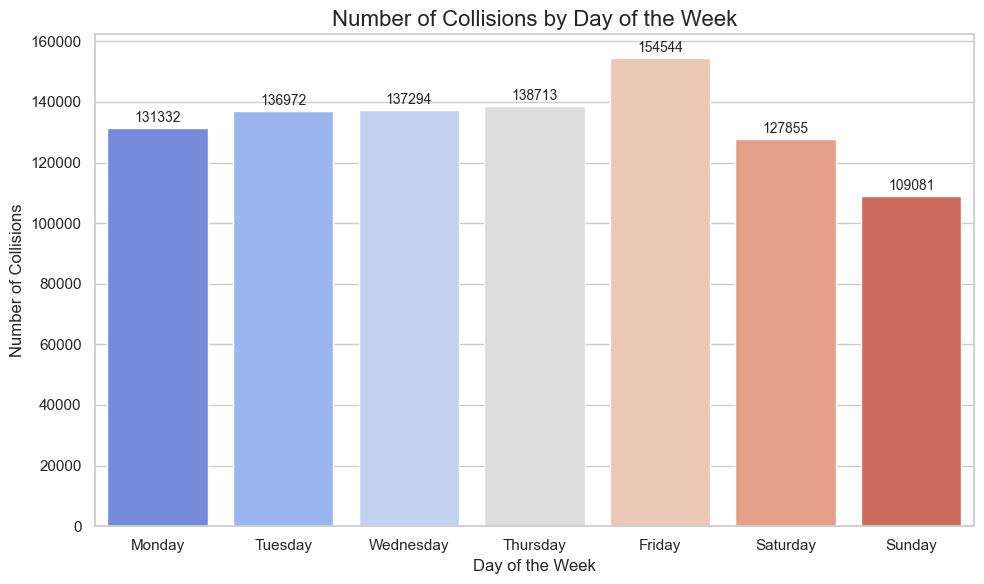

In [25]:
# Extract the weekday

# Plot

# Extract the weekday name
collisions_pd['collision_date'] = pd.to_datetime(collisions_pd['collision_date'])
collisions_pd['weekday'] = collisions_pd['collision_date'].dt.day_name()

# Order the days of the week correctly
days_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
weekday_counts = collisions_pd['weekday'].value_counts().reindex(days_order)

# Plot
plt.figure(figsize=(10, 6))
sns.barplot(x=weekday_counts.index, y=weekday_counts.values, hue=weekday_counts.index, palette='coolwarm', legend=False)

plt.title('Number of Collisions by Day of the Week', fontsize=16)
plt.xlabel('Day of the Week', fontsize=12)
plt.ylabel('Number of Collisions', fontsize=12)

# Add exact count text
for i, v in enumerate(weekday_counts.values):
    plt.text(i, v + 1000, str(v), ha='center', va='bottom', fontsize=10)

plt.tight_layout()
plt.show()


##**3.1.9. Spatial Distribution of Collisions.** <font color = red>[7 marks]</font> <br>

Q: Study spatial distribution of collisions by county.

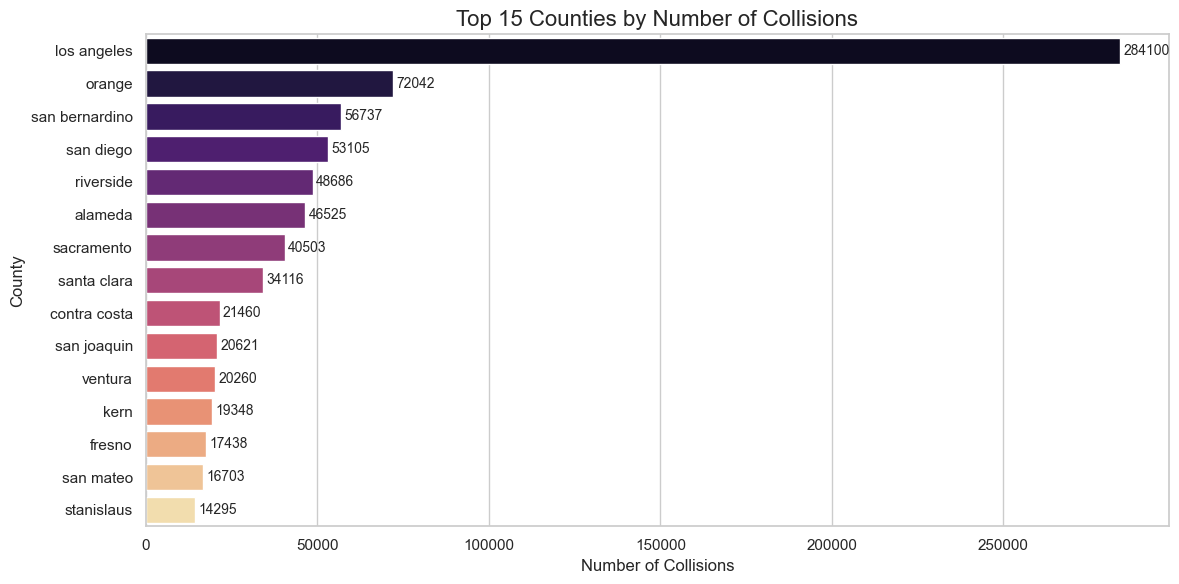

In [26]:
# Spatial Analysis

# Collision Density by County

# Plot the map

# Get top 15 counties by collision count
county_counts = collisions_pd['county_location'].value_counts().head(15)

plt.figure(figsize=(12, 6))
sns.barplot(x=county_counts.values, y=county_counts.index, hue=county_counts.index, palette='magma', legend=False)

plt.title('Top 15 Counties by Number of Collisions', fontsize=16)
plt.xlabel('Number of Collisions', fontsize=12)
plt.ylabel('County', fontsize=12)

# Add exact count text
for i, v in enumerate(county_counts.values):
    plt.text(v + 1000, i, str(v), va='center', fontsize=10)

plt.tight_layout()
plt.show()

##**3.1.10. Collision Analysis by Geography.** <font color = red>[6 marks]</font> <br>

Q: Generate a scatter plot to analyze collision locations geographically.

Collisions with valid coordinates: 266,742 of 935,791 (28.5%)


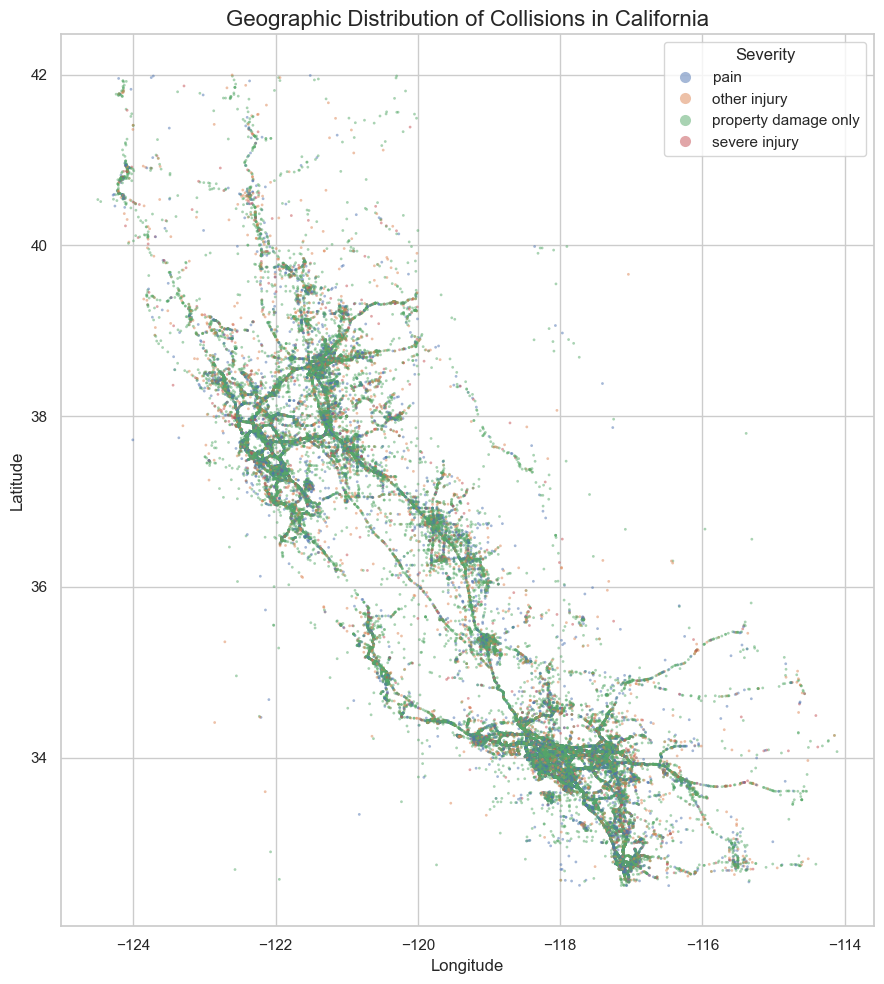

In [27]:
# Scatter Plot of Collision Locations
geo_pd = collisions_pd[['latitude', 'longitude', 'collision_severity']].copy()

# Convert to numeric and handle invalid data
geo_pd['latitude'] = pd.to_numeric(geo_pd['latitude'], errors='coerce')
geo_pd['longitude'] = pd.to_numeric(geo_pd['longitude'], errors='coerce')
geo_pd = geo_pd.dropna(subset=['latitude', 'longitude'])
geo_pd = geo_pd[geo_pd['latitude'].between(32.5, 42.1) & geo_pd['longitude'].between(-124.5, -114.1)]
print(f"Collisions with valid coordinates: {len(geo_pd):,} of {len(collisions_pd):,} ({len(geo_pd)/len(collisions_pd):.1%})")

# Plot a random sample to keep it fast and readable
plot_sample = geo_pd.sample(n=min(60000, len(geo_pd)), random_state=42)
plt.figure(figsize=(9, 10))
sns.scatterplot(data=plot_sample, x='longitude', y='latitude', hue='collision_severity', s=4, alpha=0.5, linewidth=0)
plt.title('Geographic Distribution of Collisions in California', fontsize=16)
plt.xlabel('Longitude', fontsize=12)
plt.ylabel('Latitude', fontsize=12)
plt.legend(title='Severity', markerscale=4)
plt.tight_layout()
plt.show()

##**3.1.11. Collision Trends Over Time.** <font color = red>[10 marks]</font> <br>

Extract and analyzing collision trends over time.

In [28]:
from pyspark.sql.functions import year, month, hour, to_timestamp, col

# Extract year and month from collision_date

# Plot

# Extract year, month, and hour using Pandas
collisions_pd['collision_date'] = pd.to_datetime(collisions_pd['collision_date'])
collisions_pd['collision_time'] = pd.to_datetime(collisions_pd['collision_time'])

collisions_pd['year'] = collisions_pd['collision_date'].dt.year
collisions_pd['month'] = collisions_pd['collision_date'].dt.month
collisions_pd['hour'] = collisions_pd['collision_time'].dt.hour

print("Time components extracted successfully.")

Time components extracted successfully.


Q: Analyze yearly, monthly and hourly trends in collisions.

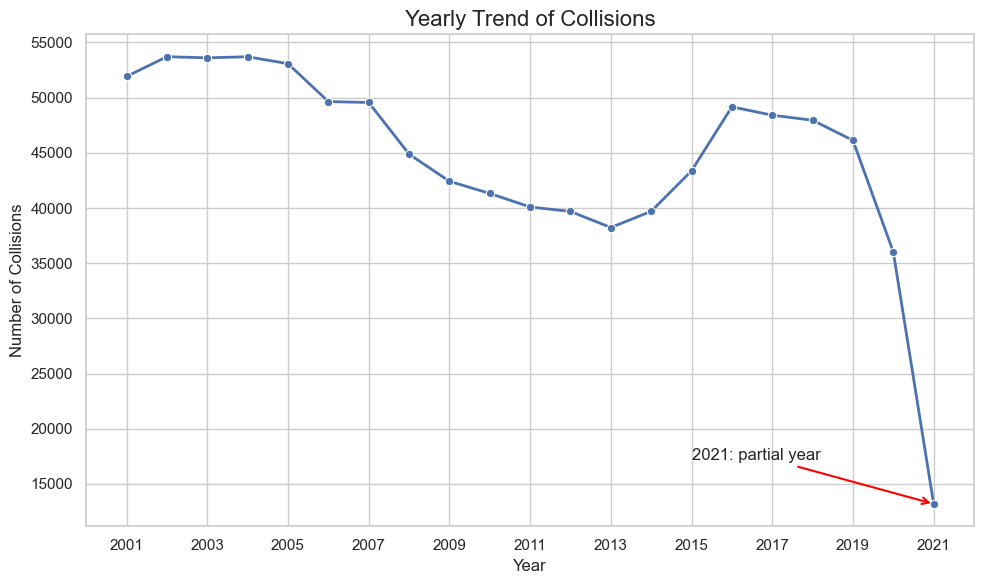

In [29]:
# Yearly Trend of Collisions

# Plot

# Plot
yearly_counts = collisions_pd['year'].value_counts().sort_index()

plt.figure(figsize=(10, 6))
sns.lineplot(x=yearly_counts.index, y=yearly_counts.values, marker='o', color='b', linewidth=2)

plt.title('Yearly Trend of Collisions', fontsize=16)
plt.xlabel('Year', fontsize=12)
plt.ylabel('Number of Collisions', fontsize=12)

# 2021 is a partial year in this dataset, so the final drop is a coverage artefact, not a real decline
plt.annotate('2021: partial year', xy=(yearly_counts.index[-1], yearly_counts.values[-1]),
             xytext=(yearly_counts.index[-1] - 6, yearly_counts.values[-1] + 4000),
             arrowprops=dict(arrowstyle='->', color='red', lw=1.5))
plt.xticks(range(int(yearly_counts.index.min()), int(yearly_counts.index.max()) + 1, 2))
plt.grid(True)
plt.tight_layout()
plt.show()


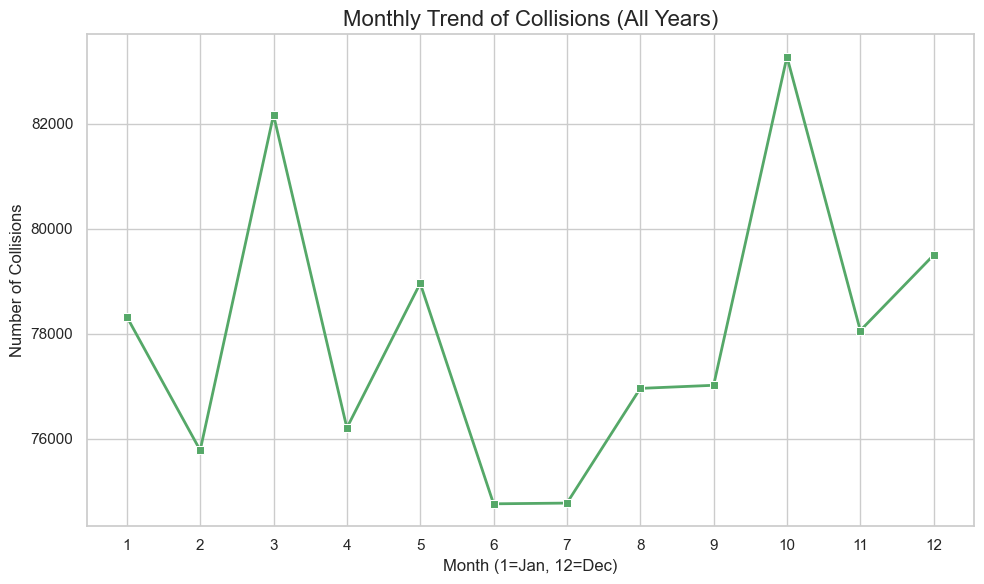

In [30]:
# Monthly Trend of Collisions

# Plot

# Plot
monthly_counts = collisions_pd['month'].value_counts().sort_index()

plt.figure(figsize=(10, 6))
sns.lineplot(x=monthly_counts.index, y=monthly_counts.values, marker='s', color='g', linewidth=2)

plt.title('Monthly Trend of Collisions (All Years)', fontsize=16)
plt.xlabel('Month (1=Jan, 12=Dec)', fontsize=12)
plt.ylabel('Number of Collisions', fontsize=12)
plt.xticks(range(1, 13)) # Show all months
plt.grid(True)
plt.tight_layout()
plt.show()


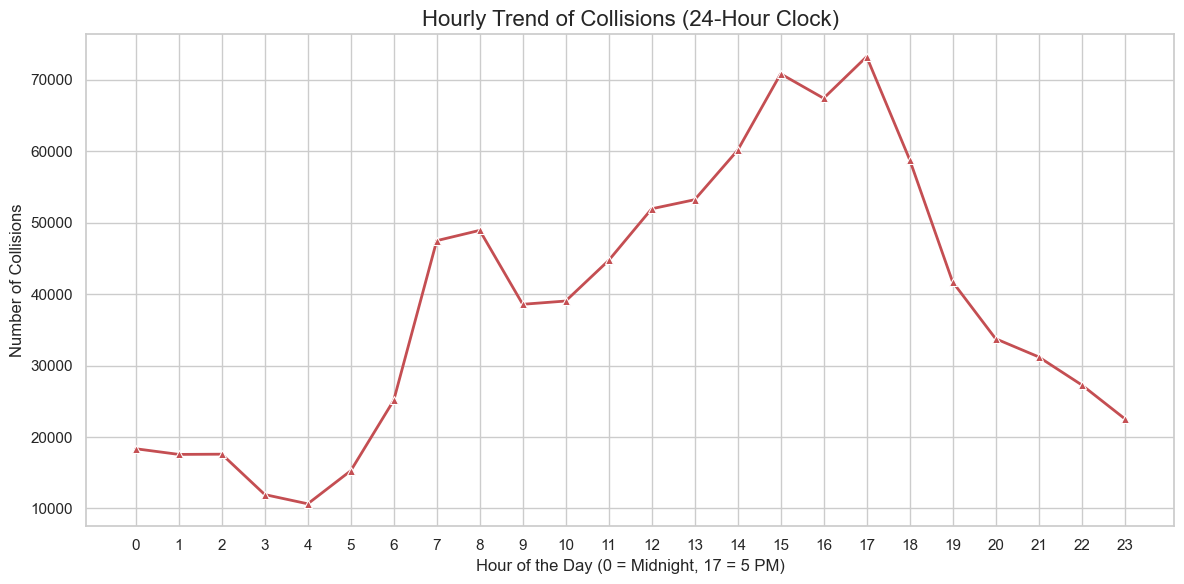

In [31]:
# Hourly Trend of Collisions

# Plot

# Plot
hourly_counts = collisions_pd['hour'].value_counts().sort_index()

plt.figure(figsize=(12, 6))
sns.lineplot(x=hourly_counts.index, y=hourly_counts.values, marker='^', color='r', linewidth=2)

plt.title('Hourly Trend of Collisions (24-Hour Clock)', fontsize=16)
plt.xlabel('Hour of the Day (0 = Midnight, 17 = 5 PM)', fontsize=12)
plt.ylabel('Number of Collisions', fontsize=12)
plt.xticks(range(0, 24)) # Show all 24 hours
plt.grid(True)
plt.tight_layout()
plt.show()


#**4. ETL Querying** <font color = red>[35 marks]</font> <br>

In [32]:
# Create a temporary view of our Spark DataFrame to run SQL queries against it
collisions_clean_df.createOrReplaceTempView("collisions")
print("Temporary SQL view 'collisions' created successfully!")

Temporary SQL view 'collisions' created successfully!


## **4.1. Top 5 Counties** <font color = red>[4 marks]</font> <br>

Q: Identify the top 5 counties with the highest number of collisions.

In [33]:
# Query: Identify the top 5 counties with the most collisions
query_4_1 = """
SELECT county_location, COUNT(*) as collision_count
FROM collisions
WHERE county_location IS NOT NULL
GROUP BY county_location
ORDER BY collision_count DESC
LIMIT 5
"""

# Execute the query using Spark SQL
spark.sql(query_4_1).show()

+---------------+---------------+
|county_location|collision_count|
+---------------+---------------+
|    los angeles|         284100|
|         orange|          72042|
| san bernardino|          56737|
|      san diego|          53105|
|      riverside|          48686|
+---------------+---------------+



## **4.2. Month with Highest Collisions** <font color = red>[5 marks]</font> <br>

Q. Identify the month with the highest number of collisions.

In [34]:
# Query: Find the month with the highest number of collisions
query_4_2 = """
SELECT month(collision_date) as Month, COUNT(*) as collision_count
FROM collisions
WHERE collision_date IS NOT NULL
GROUP BY month(collision_date)
ORDER BY collision_count DESC
LIMIT 1
"""

spark.sql(query_4_2).show()

+-----+---------------+
|Month|collision_count|
+-----+---------------+
|   10|          83274|
+-----+---------------+



## **4.3. Weather Conditions with Highest Collisions.** <font color = red>[5 marks]</font> <br>

Q. Determine the most common weather condition during collisions.

In [35]:
# Query: Find the most common weather condition during collisions

# Query: Find the most common weather condition during collisions
query_4_3 = """
SELECT weather_1, COUNT(*) as collision_count
FROM collisions
WHERE weather_1 IS NOT NULL
GROUP BY weather_1
ORDER BY collision_count DESC
LIMIT 1
"""

spark.sql(query_4_3).show()

+---------+---------------+
|weather_1|collision_count|
+---------+---------------+
|    clear|         769927|
+---------+---------------+



## **4.4. Fatal Collisions.** <font color = red>[5 marks]</font> <br>

Q. Calculate the percentage of collisions that resulted in fatalities.

In [36]:
# Query: Determine the percentage of collisions that resulted in fatalities
# Fatal = severity 'fatal' OR at least one victim killed. This sample has none, so the result is 0%.
query_4_4 = """
SELECT
    SUM(CASE WHEN collision_severity = 'fatal' OR killed_victims > 0 THEN 1 ELSE 0 END) AS fatal_count,
    COUNT(*) AS total_count,
    ROUND(100.0 * SUM(CASE WHEN collision_severity = 'fatal' OR killed_victims > 0 THEN 1 ELSE 0 END) / COUNT(*), 2) AS fatal_percentage
FROM collisions
"""
spark.sql(query_4_4).show()

# For context: severity breakdown shown separately
query_4_4b = """
SELECT collision_severity, COUNT(*) AS collision_count,
       ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (), 2) AS percentage
FROM collisions
GROUP BY collision_severity
ORDER BY collision_count DESC
"""
spark.sql(query_4_4b).show()

+-----------+-----------+----------------+
|fatal_count|total_count|fatal_percentage|
+-----------+-----------+----------------+
|          0|     935791|            0.00|
+-----------+-----------+----------------+

+--------------------+---------------+----------+
|  collision_severity|collision_count|percentage|
+--------------------+---------------+----------+
|property damage only|         570480|     60.96|
|                pain|         226492|     24.20|
|        other injury|         116681|     12.47|
|       severe injury|          22138|      2.37|
+--------------------+---------------+----------+



## **4.5. Dangerous Time for Collisions.** <font color = red>[5 marks]</font> <br>

Q. Find the most dangerous time of day for collisions.

In [37]:

# Query: Find the most dangerous time of day for collisions
query_4_5 = """
SELECT hour(collision_time) as Hour_of_Day, COUNT(*) as collision_count
FROM collisions
WHERE collision_time IS NOT NULL
GROUP BY hour(collision_time)
ORDER BY collision_count DESC
LIMIT 1
"""

spark.sql(query_4_5).show()

+-----------+---------------+
|Hour_of_Day|collision_count|
+-----------+---------------+
|         17|          73255|
+-----------+---------------+



## **4.6. Road Surface Conditions.** <font color = red>[5 marks]</font> <br>

Q. Identify the top 5 road surface conditions with the highest collision frequency.

In [38]:
# Query: List the top 5 road types with the highest collision frequency


query_4_6 = """
SELECT road_surface, COUNT(*) as collision_count
FROM collisions
WHERE road_surface IS NOT NULL
GROUP BY road_surface
ORDER BY collision_count DESC
LIMIT 5
"""

spark.sql(query_4_6).show()


+------------+---------------+
|road_surface|collision_count|
+------------+---------------+
|         dry|         845637|
|         wet|          76833|
|     Unknown|           8141|
|       snowy|           4122|
|    slippery|           1048|
+------------+---------------+



## **4.7. Lighting Conditions.** <font color = red>[5 marks]</font> <br>

Q. Analyze lighting conditions that contribute to the highest number of collisions.

In [39]:
# Query: Find the top 3 lighting conditions that lead to the most collisions

# Query: Find the top 3 lighting conditions that lead to the most collisions
query_4_7 = """
SELECT lighting, COUNT(*) as collision_count
FROM collisions
WHERE lighting IS NOT NULL
GROUP BY lighting
ORDER BY collision_count DESC
LIMIT 3
"""

spark.sql(query_4_7).show()

+--------------------+---------------+
|            lighting|collision_count|
+--------------------+---------------+
|            daylight|         625574|
|dark with street ...|         195867|
|dark with no stre...|          74634|
+--------------------+---------------+



#5. Conclusion <font color = red>[10 marks]</font> <br>

Write your conclusion.

# Final insights and recommendations

Based on the ETL process, Data Cleaning, EDA, and SQL Querying performed on the 935,791 traffic collision records, the following key insights and recommendations have been derived:

### 1. High-Risk Locations and Peak Times
*   **Insight:** Los Angeles County is by far the most dangerous zone, accounting for 284,100 collisions (about 30% of the state's total). The most dangerous time of day is 5:00 PM (73,255 collisions), directly correlating with evening rush hour. Accidents peak on Fridays and hit their lowest point on Sundays.
*   **Recommendation:** Infrastructure improvements, such as enhanced lighting and traffic signal optimization, should be prioritized in Los Angeles County. Targeted law enforcement and traffic management should be deployed specifically during the 3 PM – 6 PM window to manage the rush hour spike.

### 2. Environmental Factors (Weather, Road Surface, Lighting)
*   **Insight:** An overwhelming 82% of collisions (769,927) occur in "Clear" weather, and 90% occur on "Dry" road surfaces. Furthermore, 625,574 collisions happen in "Daylight." However, volume and severity tell different stories: on roads that are dark with no street lights, 4.35% of collisions cause severe injury, compared with 1.92% in daylight. Fog (3.59%) is also more severe than clear weather (2.42%), while rain (1.92%) is milder.
*   **Recommendation:** Most collisions happen in normal driving conditions, so public safety campaigns should not focus only on "bad weather driving," but also on speeding, distracted driving, and following distances in clear, dry conditions. At the same time, street lighting upgrades and enforcement on unlit road segments are a high-value target, because that is where crashes are most likely to cause severe injury.

### 3. Collision Severity and Victims
*   **Insight:** Only 2.37% of collisions (22,138 cases) result in severe injuries, and this sample contains no fatal collisions (0.00%). Severe crashes involve a higher average number of victims per incident than property-damage-only crashes.
*   **Recommendation:** Policy should prioritize reducing severe-injury crashes, with particular attention to pedestrian and cyclist safety in high-density urban areas; this should be examined further using the pedestrian and bicycle collision indicators in the data. Predictive models can be developed to anticipate collision hotspots based on historical severity data.

### 4. Data Quality Limitations
*   **Insight:** A significant challenge was the missing geographic data. About 71% of the latitude/longitude values were null; the 266,742 collisions with valid coordinates were retained and used for the geographic scatter plot, while other sparse columns (>60% missing) were dropped. Additionally, 4,626 collisions (about 0.5%) had no weather recorded and were labelled "Unknown".
*   **Recommendation:** The California Highway Patrol (CHP) and local agencies must upgrade their data collection protocols. Mandating GPS coordinates for every crash report and using automated weather APIs at the time of dispatch would drastically improve the accuracy of future spatial and environmental analyses.

#6. Visualization Integration using Tableau/ PowerBI <font color = red>[Optional]</font> <br>

In [40]:
# Define the path where we want to save the CSV for Tableau
tableau_csv_path = base_path + "cleaned_collisions_for_tableau.csv"

print("Exporting data for Tableau... (This may take a minute)")
# Export a copy so collisions_pd is left unchanged (cell can be re-run safely)
export_df = collisions_pd.copy()
# collision_time as a clean HH:MM:SS string (Spark attached today's date to the time values)
export_df['collision_time'] = pd.to_datetime(export_df['collision_time']).dt.strftime('%H:%M:%S')
export_df.to_csv(tableau_csv_path, index=False)

print(f"Success! Data exported to: {tableau_csv_path}")

Exporting data for Tableau... (This may take a minute)
Success! Data exported to: D:/downloads/Crash_Data_Analysis_Dataset/cleaned_collisions_for_tableau.csv
